
# Netflix Movies and TV Shows Clustering Using Machine Learning

## 1. Project Overview

Netflix offers movies and television shows across various genres, countries, release years, and content ratings. Analyzing these titles can help us understand the characteristics and patterns present in the content catalog.

This project uses Exploratory Data Analysis (EDA) and unsupervised machine learning to investigate Netflix content and identify groups of similar titles based on selected features.

## 2. Project Objectives

- Understand the structure and characteristics of the dataset.
- Perform exploratory data analysis using statistics and visualizations.
- Identify and handle data quality issues.
- Prepare suitable features for machine learning.
- Apply clustering algorithms to group similar titles.
- Evaluate the quality of the clusters.
- Interpret the results and present meaningful findings.

## 3. Project Workflow

1. Data loading and inspection
2. Exploratory Data Analysis
3. Data cleaning and preprocessing
4. Feature engineering and selection
5. Clustering model development
6. Cluster evaluation and visualization
7. Results interpretation and conclusion

## 4. Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook



## 5. Import Required Libraries

This section imports the Python libraries needed for data manipulation, numerical calculations, visualization, and machine learning.

Pandas and NumPy support data analysis, Matplotlib and Seaborn support visualization, and Scikit-learn will be used later for preprocessing and clustering.


In [1]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warning management
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


## 6. Dataset Loading

The Netflix Movies and TV Shows dataset is loaded into a Pandas DataFrame.

A DataFrame is a table containing rows and columns. Loading the dataset allows us to inspect the records, understand the available features, and determine the appropriate analysis and preprocessing steps.


In [2]:
# Load the dataset
df = pd.read_csv(
    "NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv"
)

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display the first five records
display(df.head())


Dataset Shape: (7787, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,07:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


## 7. Dataset Structure and Data Quality Analysis

This section examines the structure and quality of the Netflix dataset before performing exploratory data analysis.

The analysis focuses on:

- Identifying column names and data types.
- Checking the number of non-missing values.
- Detecting missing values in each column.
- Identifying duplicate records.

Understanding these characteristics helps determine the data cleaning and preprocessing steps required before applying machine learning algorithms.


In [3]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       7787 non-null   str  
 1   type          7787 non-null   str  
 2   title         7787 non-null   str  
 3   director      5398 non-null   str  
 4   cast          7069 non-null   str  
 5   country       7280 non-null   str  
 6   date_added    7777 non-null   str  
 7   release_year  7787 non-null   int64
 8   rating        7780 non-null   str  
 9   duration      7787 non-null   str  
 10  listed_in     7787 non-null   str  
 11  description   7787 non-null   str  
dtypes: int64(1), str(11)
memory usage: 730.2 KB


In [4]:
# Display all columns name

print("Column names:")
print(df.columns.tolist())

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']



### 7.1 Missing Value Analysis

Missing values occur when information is unavailable for particular records.

This analysis calculates the number of missing values in each column. The results will help us decide how to handle incomplete information without unnecessarily removing useful records.


In [5]:
# count missing values in each columns
missing_count = df.isnull().sum()

# calculate missing value percentage
missing_percentage = (
    missing_count / len(df) * 100
).round(2)

# Create summary table
missing_summary = pd.DataFrame({
    "Missing_count": missing_count,
    "Missing_percentage" : missing_percentage
})

# Display columns contains Missing Values

missing_summary = missing_summary[
    missing_summary["Missing_count"] > 0    
].sort_values(
    by="Missing_count",
    ascending=False
)

display(missing_summary)


,Missing_count,Missing_percentage
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09


### 7.2 Duplicate Record Analysis

Duplicate records are repeated rows containing identical values across all columns.

Checking duplicates helps assess data quality. We will review the number of duplicates before deciding whether any records need to be removed.


In [6]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is the process of examining a dataset using statistical summaries and visualizations to understand its characteristics, identify patterns, and discover potential data quality issues.

In this project, EDA is used to analyze the distribution of Netflix content, release years, content ratings, countries, and genres.

The findings from EDA will help us understand the dataset and select appropriate features for the clustering stage.



### 8.1 Distribution of Movies and TV Shows

This analysis compares the number of Movies and TV Shows in the Netflix dataset.

A count plot is used to visualize the frequency of each content type. This helps us understand the composition of the dataset and identify which content category is more common.


Content Type Distribution
type
Movie      5377
TV Show    2410
Name: count, dtype: int64


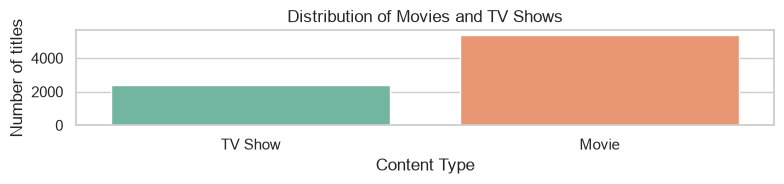

In [7]:
# Count each content type
content_counts = df["type"].value_counts()

# Display the count
print("Content Type Distribution")
print(content_counts)

# Create Visualization
plt.figure(figsize=(8,2))

sns.countplot(
    data=df,
    x="type",
    hue="type",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Movies and TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()


### 8.2 Distribution of Content by Release Year

This analysis examines the release years of movies and television shows in the dataset.

A line chart is used to display the number of titles for each release year. This helps identify years with relatively high or low numbers of titles.

Release year refers to when a title was released, not when it was added to Netflix.


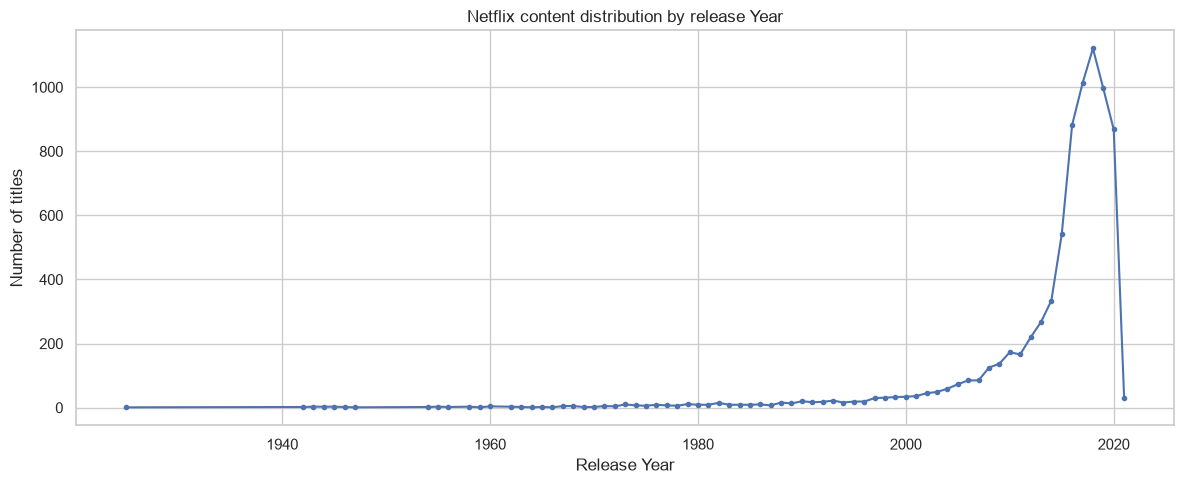

In [8]:
# Count title for each year release year
year_counts = df["release_year"].value_counts().sort_index()

# Create the chart
plt.figure(figsize=(12,5))

plt.plot(
    year_counts.index,
    year_counts.values,
    marker = "o",
    markersize = 3
)

plt.title("Netflix content distribution by release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of titles")

plt.tight_layout()
plt.show()

In [9]:
# Find the Year with the highest number of titles
highest_year = year_counts.idxmax()
highest_count = year_counts.max()

print("Year with the most titles:", highest_year)
print("Number of titles:", highest_count)

Year with the most titles: 2018
Number of titles: 1121



### 8.3 Distribution of Content Ratings

This analysis examines the content ratings assigned to Netflix titles.

A count plot is used to compare the frequency of each rating. Understanding rating distribution helps describe the audience classifications represented in the dataset.

Missing ratings will be handled during the data cleaning stage.


COntent rating Distribution
rating
TV-MA       2863
TV-14       1931
TV-PG        806
R            665
PG-13        386
TV-Y         280
TV-Y7        271
PG           247
TV-G         194
NR            84
G             39
TV-Y7-FV       6
UR             5
NC-17          3
Name: count, dtype: int64


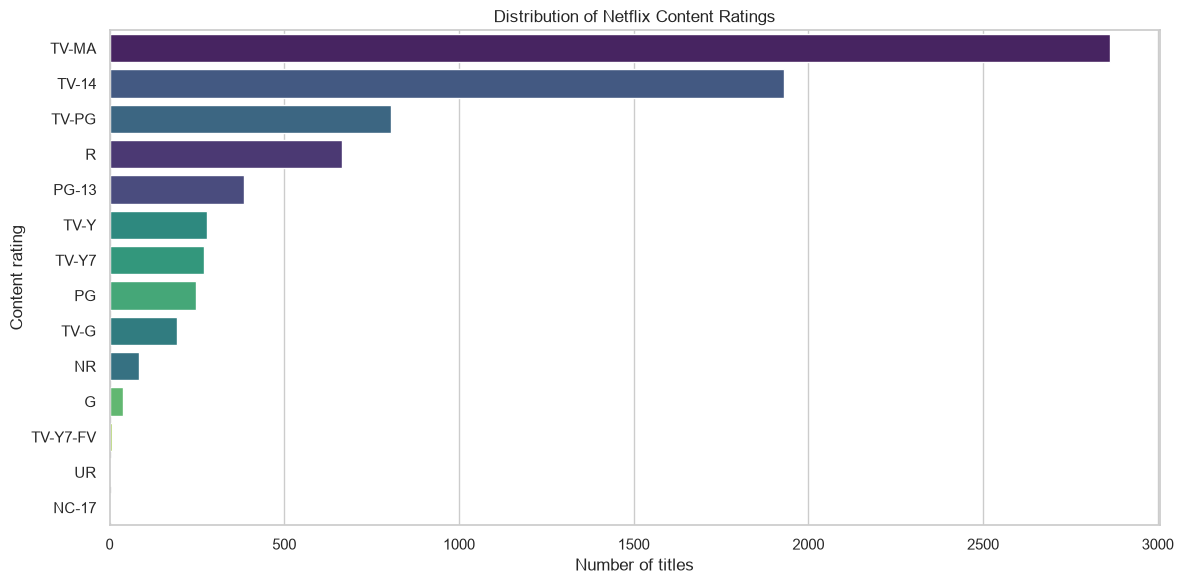

In [10]:
# Count titles for each ratings
rating_counts = df["rating"].value_counts()

# Display the rating Counts
print("COntent rating Distribution")
print(rating_counts)

# Visualize most common ratings
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    y="rating",
    order=rating_counts.index,
    hue="rating",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Netflix Content Ratings")
plt.xlabel("Number of titles")
plt.ylabel("Content rating")
plt.tight_layout()
plt.show()


### 8.4 Distribution of Netflix Genres

The `listed_in` column contains genre and category information. Some titles have multiple genres stored in the same cell, separated by commas.

This analysis separates the genre labels and counts their occurrences to identify the most frequently represented categories.

Because titles can belong to multiple genres, the total genre counts may exceed the number of titles in the dataset.


10 most genres:
listed_in
International Movies        2437
Dramas                      2106
Comedies                    1471
International TV Shows      1199
Documentaries                786
Action & Adventure           721
TV Dramas                    704
Independent Movies           673
Children & Family Movies     532
Romantic Movies              531
Name: count, dtype: int64


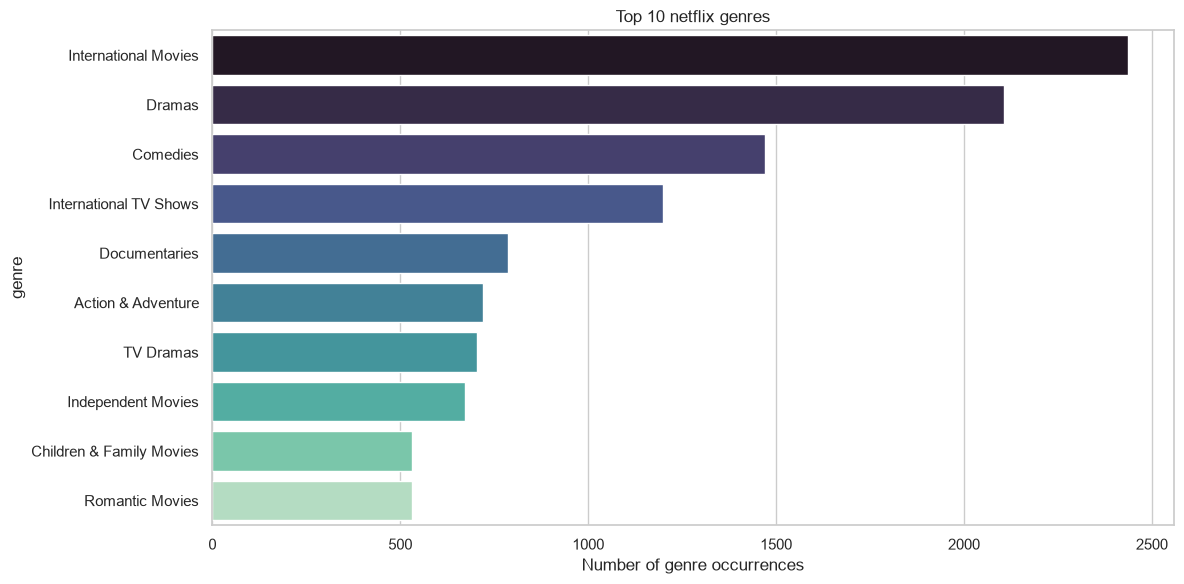

In [11]:
# Remove rows with missing genre information
genre_data = df["listed_in"].dropna()

# split comma separated values to individual values
genres = genre_data.str.split(", ").explode()

# count each genres
genre_counts = genres.value_counts()

# Display the 10 most genres
print("10 most genres:")
print(genre_counts.head(10))

# visualize the top 10 genres

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.head(10).values,
    y=genre_counts.head(10).index,
    hue=genre_counts.head(10).index,
    palette="mako",
    legend=False
)

plt.title("Top 10 netflix genres")
plt.xlabel("Number of genre occurrences")
plt.ylabel("genre")
plt.tight_layout()
plt.show()


## 9. Data Cleaning and Preparation

Data cleaning is an important stage of the data science workflow. It helps identify and handle incomplete or inconsistent information before machine learning.

In this project, data cleaning includes:

- Checking missing values and their proportions.
- Examining duplicate records.
- Converting date fields into appropriate data types.
- Inspecting categorical and numerical columns.
- Preparing relevant features for subsequent analysis.

Data will only be modified when there is a clear reason to do so. We will avoid deleting useful records unnecessarily and will document the decisions made during preprocessing.



### 9.1 Handling Missing Categorical Values

Missing values in the director, cast, country, and rating columns are replaced with "Unknown" to preserve records and explicitly represent unavailable information.

This approach avoids unnecessarily deleting titles from the dataset.


In [12]:
# Replace missing categorial values
categorial_columns = [
    "director",
    "cast",
    "country",
    "rating"
]

for column in categorial_columns:
    df[column] = df[column].fillna("Unknown")

# Validate the changes
print("Remaining missing values in selected columns:")
display(df[categorial_columns].isnull().sum())

Remaining missing values in selected columns:


director    0
cast        0
country     0
rating      0
dtype: int64


### 9.2 Date Format Conversion

The `date_added` column represents the date on which a title was added to Netflix.

This column may initially be stored as text. Converting it into a datetime data type allows us to extract date components and perform time-based analysis.

Invalid or unavailable dates will be represented as missing datetime values rather than being assigned invented dates.

In [13]:
# Convert date_added to Date Format
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce"
)

# Display the data type
print("DataType:", df["date_added"].dtype)

# Display the number of missing Dates
print("Missing_dates:", df["date_added"].isnull().sum())

# Display the sample records
display(df[["title", "date_added"]].head())

DataType: datetime64[us]
Missing_dates: 98


,title,date_added
0,3%,2020-08-14
1,07:19,2016-12-23
2,23:59,2018-12-20
3,9,2017-11-16
4,21,2020-01-01



## 10. Feature Engineering

Feature engineering involves transforming existing data into useful features for machine learning.

In this project, we will examine the duration, release year, genre, and description columns to identify useful information for clustering Netflix titles.

### 10.1 Duration Analysis

The `duration` column contains movie runtimes in minutes or the number of seasons for TV shows.

We will inspect the available values and missing entries before deciding how to transform this feature.


In [14]:

# Display the 15 most frequent duration values
print("Most Common Duration Values:")
display(df["duration"].value_counts().head(15))

# Count missing duration values
print("\nMissing Duration Values:")
print(df["duration"].isnull().sum())


Most Common Duration Values:


duration
1 Season     1608
2 Seasons     382
3 Seasons     184
90 min        136
93 min        131
91 min        125
94 min        125
95 min        119
92 min        118
97 min        117
96 min        115
98 min        106
103 min       101
99 min        101
88 min        101
Name: count, dtype: int64


Missing Duration Values:
0



### 10.2 Extracting Numeric Duration Features

The `duration` column contains different measurements for movies and TV shows. Movie durations are expressed in minutes, while TV show durations are expressed in seasons.

To make these values easier to analyze, we will extract the numeric portion and store it in a new column called `duration_value`. We will also create a `duration_unit` column to identify whether the measurement represents minutes or seasons.

Keeping the measurement unit separate prevents us from treating movie runtime and television seasons as equivalent quantities.


In [15]:

# Extract the numeric portion of duration
df["duration_value"] = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Identify the duration unit
df["duration_unit"] = np.select(
    [
        df["duration"].str.contains("min", case=False, na=False),
        df["duration"].str.contains("Season", case=False, na=False)
    ],
    [
        "Minutes",
        "Seasons"
    ],
    default="Unknown"
)

# Display the results
display(
    df[["type", "title", "duration", "duration_value", "duration_unit"]].head(10)
)


,type,title,duration,duration_value,duration_unit
0,TV Show,3%,4 Seasons,4,Seasons
1,Movie,07:19,93 min,93,Minutes
2,Movie,23:59,78 min,78,Minutes
3,Movie,9,80 min,80,Minutes
4,Movie,21,123 min,123,Minutes
5,TV Show,46,1 Season,1,Seasons
6,Movie,122,95 min,95,Minutes
7,Movie,187,119 min,119,Minutes
8,Movie,706,118 min,118,Minutes
9,Movie,1920,143 min,143,Minutes



### 10.3 Validation of Duration Features

The extracted numeric values and measurement units are checked to confirm that the transformation worked correctly.

We will inspect the distribution of duration units and count values that could not be extracted.


In [16]:

# Count records by duration unit
print("Duration Unit Distribution:")
display(df["duration_unit"].value_counts())

# Count missing numerical duration values
print("\nMissing Numeric Duration Values:")
print(df["duration_value"].isnull().sum())

# Inspect records with missing duration values
print("\nExamples of Missing Duration Values:")
display(
    df.loc[
        df["duration_value"].isnull(),
        ["type", "title", "duration"]
    ].head(10)
)


Duration Unit Distribution:


duration_unit
Minutes    5377
Seasons    2410
Name: count, dtype: int64


Missing Numeric Duration Values:
0

Examples of Missing Duration Values:


,type,title,duration



### 10.4 Genre Analysis and Feature Preparation

The `listed_in` column contains genre and category information for Netflix movies and TV shows. A title may belong to more than one genre.

This section examines the genre information and separates individual genre labels to understand the content categories represented in the dataset.

The results will help us decide how to transform genre information into features suitable for clustering.


In [17]:

# Display sample genre information
print("Sample Genre Records:")
display(df[["title", "listed_in"]].head(10))

# Count missing genre values
print("\nMissing Genre Values:")
print(df["listed_in"].isnull().sum())

# Separate individual genre labels
genre_series = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
)

# Count genre occurrences
genre_counts = genre_series.value_counts()

# Display the 10 most common genres
print("\nTop 10 Genres:")
display(genre_counts.head(10))


Sample Genre Records:


,title,listed_in
0,3%,"International TV Shows, TV Dramas, TV Sci-Fi &..."
1,07:19,"Dramas, International Movies"
2,23:59,"Horror Movies, International Movies"
3,9,"Action & Adventure, Independent Movies, Sci-Fi..."
4,21,Dramas
5,46,"International TV Shows, TV Dramas, TV Mysteries"
6,122,"Horror Movies, International Movies"
7,187,Dramas
8,706,"Horror Movies, International Movies"
9,1920,"Horror Movies, International Movies, Thrillers"



Missing Genre Values:
0

Top 10 Genres:


listed_in
International Movies        2437
Dramas                      2106
Comedies                    1471
International TV Shows      1199
Documentaries                786
Action & Adventure           721
TV Dramas                    704
Independent Movies           673
Children & Family Movies     532
Romantic Movies              531
Name: count, dtype: int64


### 10.5 Outlier Analysis

Outlier analysis helps identify numerical values that differ considerably from the rest of a dataset. In this project, the Interquartile Range (IQR) method is used to flag potential outliers in release year, movie duration, and TV show seasons.

Movie duration and TV show seasons are examined separately because they use different units.

A value flagged as an outlier is not necessarily an error. Older release years, long movies, and TV shows with many seasons may be valid records. Therefore, this analysis identifies potential outliers without automatically removing them.


In [18]:

# Define a function to identify potential outliers using the IQR method
def detect_outliers_iqr(series):
    values = pd.to_numeric(series, errors="coerce").dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    return {
        "Records_Analyzed": len(values),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(values) * 100
            if len(values) > 0 else 0
    }


# Analyze release year
outlier_results = {
    "Release Year": detect_outliers_iqr(df["release_year"])
}

# Analyze movie duration in minutes
movie_minutes = df.loc[
    (df["duration_unit"] == "Minutes"),
    "duration_value"
]
outlier_results["Movie Duration (Minutes)"] = detect_outliers_iqr(
    movie_minutes
)

# Analyze TV show duration in seasons
tv_seasons = df.loc[
    (df["duration_unit"] == "Seasons"),
    "duration_value"
]
outlier_results["TV Show Duration (Seasons)"] = detect_outliers_iqr(
    tv_seasons
)

# Display the results
outlier_summary = pd.DataFrame(outlier_results).T

display(outlier_summary.round(2))


,Records_Analyzed,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
Release Year,7787.0,2013.0,2018.0,5.0,2005.5,2025.5,745.0,9.57
Movie Duration (Minutes),5377.0,86.0,114.0,28.0,44.0,156.0,337.0,6.27
TV Show Duration (Seasons),2410.0,1.0,2.0,1.0,-0.5,3.5,236.0,9.79


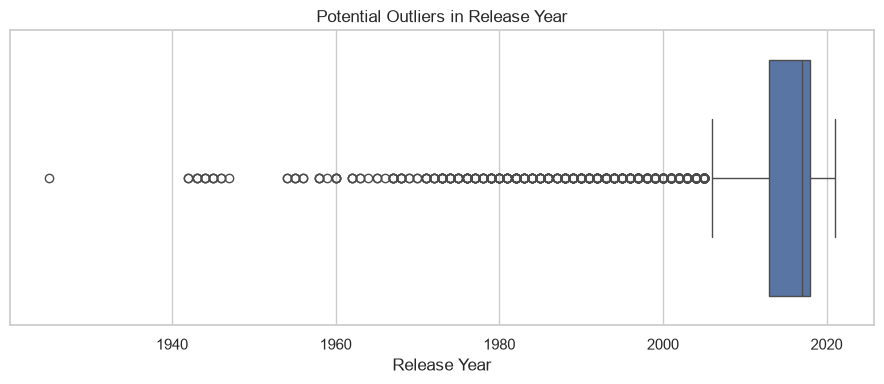

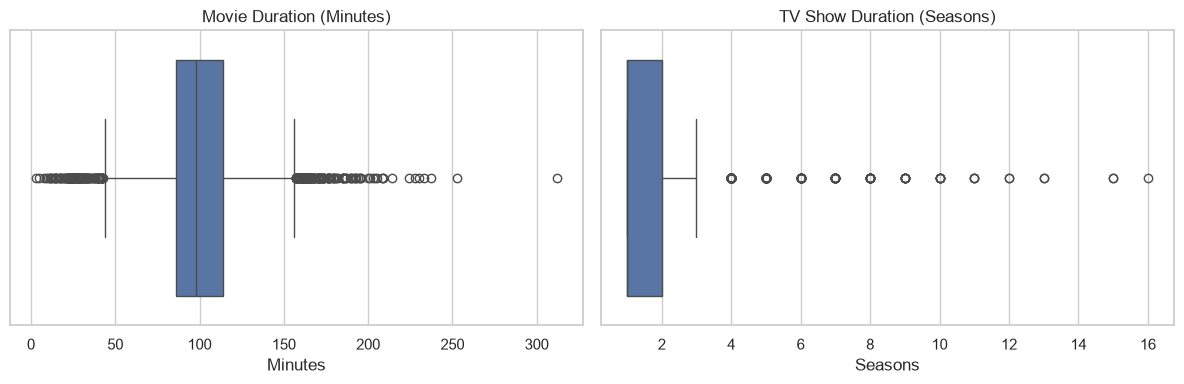

In [19]:

# Compare release years using a box plot
plt.figure(figsize=(9, 4))
sns.boxplot(x=df["release_year"])

plt.title("Potential Outliers in Release Year")
plt.xlabel("Release Year")
plt.tight_layout()
plt.show()


# Compare movie durations and TV show seasons separately
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=movie_minutes, ax=axes[0])
axes[0].set_title("Movie Duration (Minutes)")
axes[0].set_xlabel("Minutes")

sns.boxplot(x=tv_seasons, ax=axes[1])
axes[1].set_title("TV Show Duration (Seasons)")
axes[1].set_xlabel("Seasons")

plt.tight_layout()
plt.show()



### 10.6 Interpretation of Outlier Analysis

The IQR method identifies values outside the calculated lower and upper bounds as potential outliers.

The numerical summary and box plots help identify unusual release years, movie runtimes, and numbers of TV show seasons. However, these values may represent legitimate Netflix titles rather than data errors.

Therefore, potential outliers are retained unless further investigation establishes that a value is invalid. This avoids removing meaningful information from the dataset without justification.



## 11. Feature Selection and Preprocessing

### 11.1 Introduction

Feature selection identifies the variables relevant to the clustering objective. Preprocessing transforms the selected variables into a suitable format for machine learning.

In this project, we will select useful features from the Netflix dataset and prepare numerical, categorical, and textual information for clustering.

The prepared features will be used to develop and evaluate machine learning models that identify similarities among Netflix movies and TV shows.

**Objectives:**
- Identify relevant features for clustering.
- Encode categorical variables.
- Convert text into numerical representations.
- Scale numerical features where appropriate.
- Prepare a final feature matrix for clustering.



### 11.2 Inspection of Candidate Features

Before preparing the dataset for clustering, we need to understand the selected features and their data types.

The Netflix dataset contains categorical, numerical, and textual information. Each type requires an appropriate preprocessing method before it can be used by a clustering algorithm.

In this section, we will inspect the data types and missing values of the candidate features to determine the preprocessing steps required.


In [20]:

# Define candidate features
candidate_columns = [
    "type",
    "release_year",
    "rating",
    "listed_in",
    "description"
]

# Display the data types
print("Candidate Feature Data Types:")
display(df[candidate_columns].dtypes.to_frame("Data_Type"))

# Display missing-value counts
print("\nMissing Values in Candidate Features:")
display(
    df[candidate_columns]
    .isnull()
    .sum()
    .to_frame("Missing_Count")
)


Candidate Feature Data Types:


,Data_Type
type,str
release_year,int64
rating,str
listed_in,str
description,str



Missing Values in Candidate Features:


,Missing_Count
type,0
release_year,0
rating,0
listed_in,0
description,0



### 11.3 Selected Candidate Features

The following candidate features are selected for the clustering workflow:

- **type:** distinguishes Movies from TV Shows.
- **release_year:** represents the title's release year.
- **rating:** represents the content rating.
- **listed_in:** contains the genres associated with each title.
- **description:** contains a textual description of the title.

These columns are initially copied into a separate DataFrame for feature preparation.

Not all candidate features are necessarily included in the final clustering matrix. In the current implementation, genre information is encoded into binary features, type and rating are one-hot encoded, and release year is prepared as a numerical feature. The description column is not yet converted into numerical features and is therefore excluded from the current K-Means model.

This distinction ensures that the notebook accurately documents the features used by the trained model.


In [21]:

# Define the selected features
selected_columns = [
    "type",
    "release_year",
    "rating",
    "listed_in",
    "description"
]

# Create a separate dataset containing the selected features
cluster_df = df[selected_columns].copy()

# Display the selected dataset dimensions
print("Selected Dataset Shape:", cluster_df.shape)

# Display sample records
display(cluster_df.head())


Selected Dataset Shape: (7787, 5)


,type,release_year,rating,listed_in,description
0,TV Show,2020,TV-MA,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,Movie,2016,TV-MA,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,Movie,2011,R,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,Movie,2009,PG-13,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,Movie,2008,PG-13,Dramas,A brilliant group of students become card-coun...



### 11.4 Validation of the Selected Dataset

After selecting the candidate features, we verify that the resulting DataFrame contains the expected columns and records.

This validation checks the column names, dimensions, and data types. It ensures that the selected dataset is ready for the feature-encoding and preprocessing stages.

The original dataset remains unchanged because the selected features were copied into a separate DataFrame.


In [22]:

# Display the selected dataset dimensions
print("Number of Records:", cluster_df.shape[0])
print("Number of Features:", cluster_df.shape[1])

# Verify the selected column names
print("\nSelected Columns:")
print(cluster_df.columns.tolist())

# Inspect the data types
print("\nData Types:")
display(cluster_df.dtypes.to_frame("Data_Type"))

# Check missing values
print("\nMissing Values:")
display(cluster_df.isnull().sum().to_frame("Missing_Count"))


Number of Records: 7787
Number of Features: 5

Selected Columns:
['type', 'release_year', 'rating', 'listed_in', 'description']

Data Types:


,Data_Type
type,str
release_year,int64
rating,str
listed_in,str
description,str



Missing Values:


,Missing_Count
type,0
release_year,0
rating,0
listed_in,0
description,0



### 11.5 Genre Feature Encoding

The `listed_in` column contains one or more genres for each Netflix title, such as dramas, comedies, documentaries, and international movies.

Machine learning algorithms require numerical representations of features. Therefore, we use `MultiLabelBinarizer` to transform each title's genres into separate binary columns.

Each genre column contains:
- `1` if the title belongs to that genre.
- `0` if the title does not belong to that genre.

This representation allows the clustering algorithm to compare Netflix titles based on their genre similarities.


In [23]:
from sklearn.preprocessing import MultiLabelBinarizer

# Convert the genre strings into lists
genre_lists = (
    cluster_df["listed_in"]
    .fillna("")
    .apply(lambda genres: [genre.strip() for genre in genres.split(",") if genre.strip()])
)

# Create binary columns for each genre
genre_encoder = MultiLabelBinarizer()
genre_encoded = genre_encoder.fit_transform(genre_lists)

# Store the encoded features in a DataFrame
genre_df = pd.DataFrame(
    genre_encoded,
    columns=[f"genre_{genre}" for genre in genre_encoder.classes_],
    index=cluster_df.index
)

print("Number of Unique Genres:", len(genre_encoder.classes_))
print("Encoded Genre Matrix Shape:", genre_df.shape)

display(genre_df.head())


Number of Unique Genres: 42
Encoded Genre Matrix Shape: (7787, 42)


,genre_Action & Adventure,genre_Anime Features,genre_Anime Series,genre_British TV Shows,genre_Children & Family Movies,genre_Classic & Cult TV,genre_Classic Movies,genre_Comedies,genre_Crime TV Shows,genre_Cult Movies,genre_Documentaries,genre_Docuseries,genre_Dramas,genre_Faith & Spirituality,genre_Horror Movies,genre_Independent Movies,genre_International Movies,genre_International TV Shows,genre_Kids' TV,genre_Korean TV Shows,genre_LGBTQ Movies,genre_Movies,genre_Music & Musicals,genre_Reality TV,genre_Romantic Movies,genre_Romantic TV Shows,genre_Sci-Fi & Fantasy,genre_Science & Nature TV,genre_Spanish-Language TV Shows,genre_Sports Movies,genre_Stand-Up Comedy,genre_Stand-Up Comedy & Talk Shows,genre_TV Action & Adventure,genre_TV Comedies,genre_TV Dramas,genre_TV Horror,genre_TV Mysteries,genre_TV Sci-Fi & Fantasy,genre_TV Shows,genre_TV Thrillers,genre_Teen TV Shows,genre_Thrillers
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [24]:

# Check whether the encoded matrix contains only binary values
print("Unique Encoded Values:", np.unique(genre_encoded))

# Check the number of records before and after encoding
print("Original Selected Records:", len(cluster_df))
print("Encoded Genre Records:", len(genre_df))

# Display the genre names
print("\nEncoded Genre Columns:")
print(genre_df.columns.tolist())


Unique Encoded Values: [0 1]
Original Selected Records: 7787
Encoded Genre Records: 7787

Encoded Genre Columns:
['genre_Action & Adventure', 'genre_Anime Features', 'genre_Anime Series', 'genre_British TV Shows', 'genre_Children & Family Movies', 'genre_Classic & Cult TV', 'genre_Classic Movies', 'genre_Comedies', 'genre_Crime TV Shows', 'genre_Cult Movies', 'genre_Documentaries', 'genre_Docuseries', 'genre_Dramas', 'genre_Faith & Spirituality', 'genre_Horror Movies', 'genre_Independent Movies', 'genre_International Movies', 'genre_International TV Shows', "genre_Kids' TV", 'genre_Korean TV Shows', 'genre_LGBTQ Movies', 'genre_Movies', 'genre_Music & Musicals', 'genre_Reality TV', 'genre_Romantic Movies', 'genre_Romantic TV Shows', 'genre_Sci-Fi & Fantasy', 'genre_Science & Nature TV', 'genre_Spanish-Language TV Shows', 'genre_Sports Movies', 'genre_Stand-Up Comedy', 'genre_Stand-Up Comedy & Talk Shows', 'genre_TV Action & Adventure', 'genre_TV Comedies', 'genre_TV Dramas', 'genre_TV 


### 11.6 Categorical Feature Encoding

The Netflix dataset contains categorical features such as `type` and `rating`.

The `type` column identifies whether a title is a Movie or a TV Show. The `rating` column represents the content rating assigned to a title.

We use `OneHotEncoder` to convert these categorical features into numerical binary columns. This allows the clustering algorithm to use the information without treating category labels as numerical rankings.

Missing categorical values are handled by assigning them the label `Unknown` before encoding.


In [25]:
from sklearn.preprocessing import OneHotEncoder

# Select categorical features
categorical_features = cluster_df[["type", "rating"]].copy()

# Replace missing values
categorical_features = categorical_features.fillna("Unknown")

# Create the encoder
categorical_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Convert categorical features into binary columns
categorical_encoded = categorical_encoder.fit_transform(categorical_features)

# Create a DataFrame with descriptive column names
categorical_df = pd.DataFrame(
    categorical_encoded,
    columns=categorical_encoder.get_feature_names_out(["type", "rating"]),
    index=cluster_df.index
)

print("Encoded Categorical Shape:", categorical_df.shape)
display(categorical_df.head())


Encoded Categorical Shape: (7787, 17)


,type_Movie,type_TV Show,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR,rating_Unknown
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:

# Check the dimensions and column names
print("Number of Records:", categorical_df.shape[0])
print("Number of Encoded Features:", categorical_df.shape[1])

print("\nEncoded Column Names:")
print(categorical_df.columns.tolist())

# Verify that all encoded values are binary
print("\nUnique Values:")
print(np.unique(categorical_df.to_numpy()))


Number of Records: 7787
Number of Encoded Features: 17

Encoded Column Names:
['type_Movie', 'type_TV Show', 'rating_G', 'rating_NC-17', 'rating_NR', 'rating_PG', 'rating_PG-13', 'rating_R', 'rating_TV-14', 'rating_TV-G', 'rating_TV-MA', 'rating_TV-PG', 'rating_TV-Y', 'rating_TV-Y7', 'rating_TV-Y7-FV', 'rating_UR', 'rating_Unknown']

Unique Values:
[0. 1.]



### 11.7 Numerical Feature Preparation

The `release_year` column represents the year in which a Netflix title was released. Unlike categorical features, this column contains numerical values.

Before using this feature in clustering, we check its data type, missing values, and statistical distribution. We then convert it to a numeric format and handle any invalid or missing values.

This step ensures that the release year can be incorporated into the numerical feature matrix.


In [27]:

# Create a copy of the release year feature
release_year_df = cluster_df[["release_year"]].copy()

# Convert the column to numeric values
release_year_df["release_year"] = pd.to_numeric(
    release_year_df["release_year"],
    errors="coerce"
)

# Inspect the feature
print("Data Type:")
print(release_year_df["release_year"].dtype)

print("\nMissing Values:")
print(release_year_df["release_year"].isnull().sum())

print("\nStatistical Summary:")
display(release_year_df.describe())


Data Type:
int64

Missing Values:
0

Statistical Summary:


,release_year
count,7787.000000
mean,2013.932580
std,8.757395
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2018.000000
max,2021.000000


In [28]:

# Fill missing release years with the median
release_year_median = release_year_df["release_year"].median()

release_year_df["release_year"] = release_year_df["release_year"].fillna(
    release_year_median
)

print("Missing Values After Imputation:",
      release_year_df["release_year"].isnull().sum())

print("Median Release Year Used:", release_year_median)


Missing Values After Imputation: 0
Median Release Year Used: 2017.0



### 11.8 Combining Processed Features

In the previous sections, we prepared three groups of features:

- **Genre features:** binary columns representing the genres associated with each title.
- **Categorical features:** binary columns representing the title type and content rating.
- **Numerical feature:** the cleaned release year.

We now combine these feature groups into a single DataFrame. This creates a unified numerical representation that can be used in the next preprocessing and clustering stages.

The original dataset is not modified.


In [29]:

# Combine all prepared feature groups
feature_df = pd.concat(
    [
        genre_df,
        categorical_df,
        release_year_df
    ],
    axis=1
)

# Display the dimensions of the combined feature matrix
print("Combined Feature Matrix Shape:", feature_df.shape)

# Inspect the first five records
display(feature_df.head())


Combined Feature Matrix Shape: (7787, 60)


,genre_Action & Adventure,genre_Anime Features,genre_Anime Series,genre_British TV Shows,genre_Children & Family Movies,genre_Classic & Cult TV,genre_Classic Movies,genre_Comedies,genre_Crime TV Shows,genre_Cult Movies,genre_Documentaries,genre_Docuseries,genre_Dramas,genre_Faith & Spirituality,genre_Horror Movies,genre_Independent Movies,genre_International Movies,genre_International TV Shows,genre_Kids' TV,genre_Korean TV Shows,genre_LGBTQ Movies,genre_Movies,genre_Music & Musicals,genre_Reality TV,genre_Romantic Movies,genre_Romantic TV Shows,genre_Sci-Fi & Fantasy,genre_Science & Nature TV,genre_Spanish-Language TV Shows,genre_Sports Movies,genre_Stand-Up Comedy,genre_Stand-Up Comedy & Talk Shows,genre_TV Action & Adventure,genre_TV Comedies,genre_TV Dramas,genre_TV Horror,genre_TV Mysteries,genre_TV Sci-Fi & Fantasy,genre_TV Shows,genre_TV Thrillers,genre_Teen TV Shows,genre_Thrillers,type_Movie,type_TV Show,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR,rating_Unknown,release_year
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2020
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2016
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2011
3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2009
4,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2008


In [30]:

# Check whether the combined matrix has missing values
print("Total Missing Values:", feature_df.isnull().sum().sum())

# Check for duplicate column names
print("Duplicate Column Names:", feature_df.columns.duplicated().sum())

# Check data types
print("\nFeature Data Types:")
display(feature_df.dtypes.value_counts().to_frame("Column_Count"))

# Confirm the number of records
print("\nNumber of Records:", feature_df.shape[0])


Total Missing Values: 0
Duplicate Column Names: 0

Feature Data Types:


,Column_Count
int64,43
float64,17



Number of Records: 7787


In [31]:

# Verify which feature groups are included in the model
print("Genre features:", genre_df.shape[1])
print("Categorical features:", categorical_df.shape[1])
print("Numerical features:", release_year_df.shape[1])

print("\nFinal feature matrix shape:", feature_df.shape)
print("Description included:", "description" in feature_df.columns)

Genre features: 42
Categorical features: 17
Numerical features: 1

Final feature matrix shape: (7787, 60)
Description included: False



### 11.9 Feature Scaling

Feature scaling transforms numerical features to a comparable scale. This is important for distance-based clustering algorithms such as K-Means because features with larger numerical ranges can dominate distance calculations.

In our feature matrix, the `release_year` values are much larger than the binary genre and categorical features, which contain only 0s and 1s.

We use `StandardScaler` to standardize the features so that each feature has a mean close to 0 and a standard deviation close to 1. Scaling helps prevent the release year from dominating the clustering results solely because of its numerical magnitude.


In [32]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardize the combined feature matrix
scaled_features = scaler.fit_transform(feature_df)

# Convert the scaled array back into a DataFrame
scaled_feature_df = pd.DataFrame(
    scaled_features,
    columns=feature_df.columns,
    index=feature_df.index
)

print("Scaled Feature Matrix Shape:", scaled_feature_df.shape)
display(scaled_feature_df.head())


Scaled Feature Matrix Shape: (7787, 60)


,genre_Action & Adventure,genre_Anime Features,genre_Anime Series,genre_British TV Shows,genre_Children & Family Movies,genre_Classic & Cult TV,genre_Classic Movies,genre_Comedies,genre_Crime TV Shows,genre_Cult Movies,genre_Documentaries,genre_Docuseries,genre_Dramas,genre_Faith & Spirituality,genre_Horror Movies,genre_Independent Movies,genre_International Movies,genre_International TV Shows,genre_Kids' TV,genre_Korean TV Shows,genre_LGBTQ Movies,genre_Movies,genre_Music & Musicals,genre_Reality TV,genre_Romantic Movies,genre_Romantic TV Shows,genre_Sci-Fi & Fantasy,genre_Science & Nature TV,genre_Spanish-Language TV Shows,genre_Sports Movies,genre_Stand-Up Comedy,genre_Stand-Up Comedy & Talk Shows,genre_TV Action & Adventure,genre_TV Comedies,genre_TV Dramas,genre_TV Horror,genre_TV Mysteries,genre_TV Sci-Fi & Fantasy,genre_TV Shows,genre_TV Thrillers,genre_Teen TV Shows,genre_Thrillers,type_Movie,type_TV Show,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR,rating_Unknown,release_year
0,-0.319434,-0.085871,-0.139191,-0.175237,-0.270793,-0.058986,-0.115778,-0.482598,-0.240866,-0.087376,-0.335067,-0.217909,-0.608859,-0.085871,-0.204302,-0.307575,-0.674918,2.344052,-0.236962,-0.140147,-0.108134,-0.085109,-0.207352,-0.171306,-0.27052,-0.211362,-0.169711,-0.105053,-0.138711,-0.160686,-0.210033,-0.081992,-0.140147,-0.268876,3.171920,-0.094552,-0.108134,10.072762,-0.039286,-0.080389,-0.088119,-0.259417,-1.493694,1.493694,-0.070948,-0.019632,-0.104426,-0.180993,-0.228375,-0.305569,-0.574236,-0.159843,1.311440,-0.339789,-0.193128,-0.189885,-0.027769,-0.025348,-0.029996,0.692878
1,-0.319434,-0.085871,-0.139191,-0.175237,-0.270793,-0.058986,-0.115778,-0.482598,-0.240866,-0.087376,-0.335067,-0.217909,1.642416,-0.085871,-0.204302,-0.307575,1.481662,-0.426612,-0.236962,-0.140147,-0.108134,-0.085109,-0.207352,-0.171306,-0.27052,-0.211362,-0.169711,-0.105053,-0.138711,-0.160686,-0.210033,-0.081992,-0.140147,-0.268876,-0.315266,-0.094552,-0.108134,-0.099278,-0.039286,-0.080389,-0.088119,-0.259417,0.669481,-0.669481,-0.070948,-0.019632,-0.104426,-0.180993,-0.228375,-0.305569,-0.574236,-0.159843,1.311440,-0.339789,-0.193128,-0.189885,-0.027769,-0.025348,-0.029996,0.236092
2,-0.319434,-0.085871,-0.139191,-0.175237,-0.270793,-0.058986,-0.115778,-0.482598,-0.240866,-0.087376,-0.335067,-0.217909,-0.608859,-0.085871,4.894725,-0.307575,1.481662,-0.426612,-0.236962,-0.140147,-0.108134,-0.085109,-0.207352,-0.171306,-0.27052,-0.211362,-0.169711,-0.105053,-0.138711,-0.160686,-0.210033,-0.081992,-0.140147,-0.268876,-0.315266,-0.094552,-0.108134,-0.099278,-0.039286,-0.080389,-0.088119,-0.259417,0.669481,-0.669481,-0.070948,-0.019632,-0.104426,-0.180993,-0.228375,3.272579,-0.574236,-0.159843,-0.762521,-0.339789,-0.193128,-0.189885,-0.027769,-0.025348,-0.029996,-0.334890
3,3.130539,-0.085871,-0.139191,-0.175237,-0.270793,-0.058986,-0.115778,-0.482598,-0.240866,-0.087376,-0.335067,-0.217909,-0.608859,-0.085871,-0.204302,3.251243,-0.674918,-0.426612,-0.236962,-0.140147,-0.108134,-0.085109,-0.207352,-0.171306,-0.27052,-0.211362,5.892384,-0.105053,-0.138711,-0.160686,-0.210033,-0.081992,-0.140147,-0.268876,-0.315266,-0.094552,-0.108134,-0.099278,-0.039286,-0.080389,-0.088119,-0.259417,0.669481,-0.669481,-0.070948,-0.019632,-0.104426,-0.180993,4.378764,-0.305569,-0.574236,-0.159843,-0.762521,-0.339789,-0.193128,-0.189885,-0.027769,-0.025348,-0.029996,-0.563284
4,-0.319434,-0.085871,-0.139191,-0.175237,-0.270793,-0.058986,-0.115778,-0.482598,-0.240866,-0.087376,-0.335067,-0.217909,1.642416,-0.085871,-0.204302,-0.307575,-0.674918,-0.426612,-0.236962,-0.140147,-0.108134,-0.085109,-0.207352,-0.171306,-0.27052,-0.211362,-0.169711,-0.105053,-0.138711,-0.160686,-0.210033,-0.081992,-0.140147,-0.268876,-0.315266,-0.094552,-0.108134,-0.099278,-0.039286,-0.080389,-0.088119,-0.259417,0.669481,-0.669481,-0.070948,-0.019632,-0.104426,-0.180993,4.378764,-0.305

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# 1. Initialize TF-IDF Vectorizer for the description column
tfidf = TfidfVectorizer(stop_words='english', max_features=5000)

# 2. Fit and transform the descriptions
description_tfidf = tfidf.fit_transform(cluster_df['description'].fillna(""))

# 3. Combine your existing scaled features with the TF-IDF description features
combined_features_matrix = hstack([scaled_feature_df.to_numpy(), description_tfidf])

print("Combined feature matrix shape with descriptions:", combined_features_matrix.shape)

Combined feature matrix shape with descriptions: (7787, 5060)


In [34]:

# Check dimensions and missing values
print("Shape:", scaled_feature_df.shape)
print("Missing Values:", scaled_feature_df.isnull().sum().sum())

# Inspect the scaled feature statistics
display(scaled_feature_df.describe().loc[["mean", "std", "min", "max"]])


Shape: (7787, 60)
Missing Values: 0


,genre_Action & Adventure,genre_Anime Features,genre_Anime Series,genre_British TV Shows,genre_Children & Family Movies,genre_Classic & Cult TV,genre_Classic Movies,genre_Comedies,genre_Crime TV Shows,genre_Cult Movies,genre_Documentaries,genre_Docuseries,genre_Dramas,genre_Faith & Spirituality,genre_Horror Movies,genre_Independent Movies,genre_International Movies,genre_International TV Shows,genre_Kids' TV,genre_Korean TV Shows,genre_LGBTQ Movies,genre_Movies,genre_Music & Musicals,genre_Reality TV,genre_Romantic Movies,genre_Romantic TV Shows,genre_Sci-Fi & Fantasy,genre_Science & Nature TV,genre_Spanish-Language TV Shows,genre_Sports Movies,genre_Stand-Up Comedy,genre_Stand-Up Comedy & Talk Shows,genre_TV Action & Adventure,genre_TV Comedies,genre_TV Dramas,genre_TV Horror,genre_TV Mysteries,genre_TV Sci-Fi & Fantasy,genre_TV Shows,genre_TV Thrillers,genre_Teen TV Shows,genre_Thrillers,type_Movie,type_TV Show,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR,rating_Unknown,release_year
mean,7.756021e-18,1.824946e-17,-2.919914e-17,-2.965537e-17,-2.281183e-17,2.372430e-17,2.919914e-17,3.376150e-17,2.372430e-17,7.299784e-18,-2.235559e-17,6.159193e-17,1.459957e-17,3.649892e-17,6.752300e-17,-1.277462e-17,-4.379870e-17,2.098688e-17,-2.919914e-17,2.919914e-17,-3.832387e-17,-2.463677e-17,-3.102408e-17,1.277462e-17,-5.839827e-17,5.657333e-17,-6.387311e-18,-1.824946e-18,4.014881e-17,-4.197376e-17,0.000000,1.459957e-17,2.554924e-17,1.049344e-17,1.916193e-17,-3.330526e-17,-4.014881e-17,-1.277462e-17,-8.212257e-18,-4.562365e-18,7.299784e-18,2.646172e-17,1.368710e-16,-8.212257e-17,-1.277462e-17,0.000000,-4.106129e-17,-2.737419e-18,1.824946e-17,3.649892e-18,-3.649892e-18,-6.022322e-17,-2.372430e-17,-4.699236e-17,5.201096e-17,-3.832387e-17,2.737419e-18,1.231839e-17,1.824946e-17,1.003173e-14
std,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00,1.000064e+00
min,-3.194338e-01,-8.587123e-02,-1.391915e-01,-1.752374e-01,-2.707928e-01,-5.898628e-02,-1.157777e-01,-4.825977e-01,-2.408657e-01,-8.737606e-02,-3.350667e-01,-2.179095e-01,-6.088591e-01,-8.587123e-02,-2.043016e-01,-3.075747e-01,-6.749178e-01,-4.266117e-01,-2.369616e-01,-1.401471e-01,-1.081336e-01,-8.510914e-02,-2.073521e-01,-1.713058e-01,-2.705195e-01,-2.113622e-01,-1.697106e-01,-1.050528e-01,-1.387113e-01,-1.606862e-01,-0.210033,-8.199201e-02,-1.401471e-01,-2.688757e-01,-3.152664e-01,-9.455231e-02,-1.081336e-01,-9.927764e-02,-3.928624e-02,-8.038938e-02,-8.811912e-02,-2.594169e-01,-1.493694e+00,-6.694814e-01,-7.094757e-02,-0.019632,-1.044263e-01,-1.809934e-01,-2.283749e-01,-3.055694e-01,-5.742362e-01,-1.598432e-01,-7.625207e-01,-3.397885e-01,-1.931283e-01,-1.898853e-01,-2.776885e-02,-2.534775e-02,-2.999572e-02,-1.015579e+01
max,3.130539e+00,1.164534e+01,7.184349e+00,5.706545e+00,3.692860e+00,1.695309e+01,8.637242e+00,2.072119e+00,4.151690e+00,1.144478e+01,2.984481e+00,4.589062e+00,1.642416e+00,1.164534e+01,4.894725e+00,3.251243e+00,1.481662e+00,2.344052e+00,4.220092e+00,7.135358e+00,9.247823e+00,1.174962e+01,4.822714e+00,5.837515e+00,3.696591e+00,4.731214e+00,5.892384e+00,9.519021e+00,7.209216e+00,6.223310e+00,4.761165,1.219631e+01,7.135358e+00,3.719191e+00,3.171920e+00,1.05761


### 11.10 Final Preprocessing Validation

Before applying clustering algorithms, we perform a final validation of the preprocessed feature matrix.

This step confirms that the data has the expected dimensions, contains no missing or infinite values, and is stored in a numerical format suitable for machine learning.

The validated matrix, `scaled_feature_df`, will be used as the input for the clustering stage.


In [35]:

# Check the final feature matrix dimensions
print("Final Feature Matrix Shape:", scaled_feature_df.shape)

# Check for missing values
print("Total Missing Values:", scaled_feature_df.isnull().sum().sum())

# Check for infinite values
print(
    "Total Infinite Values:",
    np.isinf(scaled_feature_df.to_numpy()).sum()
)

# Check data types
print("\nData Types:")
display(scaled_feature_df.dtypes.value_counts().to_frame("Column_Count"))

# Check whether all values are numeric
print(
    "\nAll Features Numeric:",
    all(pd.api.types.is_numeric_dtype(dtype)
        for dtype in scaled_feature_df.dtypes)
)


Final Feature Matrix Shape: (7787, 60)
Total Missing Values: 0
Total Infinite Values: 0

Data Types:


,Column_Count
float64,60



All Features Numeric: True



## 12. Determining the Optimal Number of Clusters

### 12.1 Introduction to the Elbow Method

K-Means is an unsupervised machine learning algorithm that groups similar data points into clusters. However, it requires the number of clusters to be specified before training.

The Elbow Method helps identify a suitable number of clusters by comparing the Within-Cluster Sum of Squares (WCSS), also known as inertia, for different values of K.

As K increases, inertia generally decreases. We plot inertia against the number of clusters and look for an elbow point where the reduction begins to slow down.

This method provides a useful estimate, but the final choice should also consider cluster interpretability and other evaluation metrics.



### 12.2 Calculating Inertia for Different Cluster Counts

We train K-Means models using different numbers of clusters, from 2 to 10. For each model, we record its inertia to understand how compact the resulting clusters are.

We use a fixed random seed to make the results reproducible. Because the feature matrix contains thousands of records and many encoded columns, we use multiple initializations to improve the reliability of the K-Means solution.


In [36]:

from sklearn.cluster import KMeans

# Define the range of cluster counts to evaluate
k_values = range(2, 11)

# Store the inertia values
inertia_values = []

# Train a K-Means model for each K value
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_feature_df)
    inertia_values.append(kmeans.inertia_)

print("K values:", list(k_values))
print("Inertia values:", inertia_values)


K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Inertia values: [430759.81270665524, 420512.06971832016, 408783.6009519223, 399235.02332107985, 389377.4417550341, 380257.5174445191, 366575.74023894675, 363740.3908521879, 354199.23832364345]



### 12.3 Elbow Curve Visualization

The Elbow Curve displays the number of clusters on the x-axis and inertia on the y-axis.

We examine the curve to identify a point where adding more clusters produces diminishing improvements in cluster compactness.


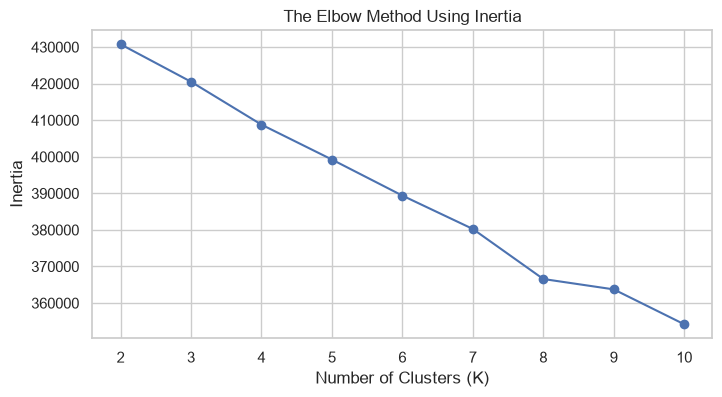

In [37]:
import matplotlib.pyplot as plt

# Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertia_values, marker="o", color="b")
plt.title("The Elbow Method Using Inertia")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()


### 12.4 Selecting the Number of Clusters

The optimal number of clusters is estimated by examining the Elbow Curve generated in Section 12.3.

The selected value of K should balance cluster compactness and model simplicity. The elbow point is where the reduction in inertia begins to slow noticeably.

The final choice will be evaluated further using the Silhouette Score and by examining the resulting clusters.



### 12.5 Silhouette Score Evaluation

The Silhouette Score measures how similar a data point is to its own cluster compared with other clusters.

The score ranges from -1 to 1:

- **Close to 1:** The data point is well matched to its own cluster.
- **Close to 0:** The data point lies near a cluster boundary.
- **Below 0:** The data point may be assigned to an unsuitable cluster.

We calculate the Silhouette Score for different values of K to compare cluster separation and cohesion. Because the dataset contains thousands of records and many encoded features, we use a reproducible sample to reduce computation time.


In [38]:

from sklearn.metrics import silhouette_score

# Create a reproducible sample for evaluation
sample_size = min(2000, len(scaled_feature_df))

silhouette_sample = scaled_feature_df.sample(
    n=sample_size,
    random_state=42
)

# Evaluate candidate cluster counts
silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(scaled_feature_df)

    sample_labels = model.predict(silhouette_sample)

    score = silhouette_score(
        silhouette_sample,
        sample_labels
    )

    silhouette_values.append(score)

    print(f"K = {k}: Silhouette Score = {score:.4f}")


K = 2: Silhouette Score = 0.1676
K = 3: Silhouette Score = 0.1717
K = 4: Silhouette Score = 0.1353
K = 5: Silhouette Score = 0.0588
K = 6: Silhouette Score = 0.0819
K = 7: Silhouette Score = 0.0759
K = 8: Silhouette Score = 0.0847
K = 9: Silhouette Score = 0.0684
K = 10: Silhouette Score = 0.1055


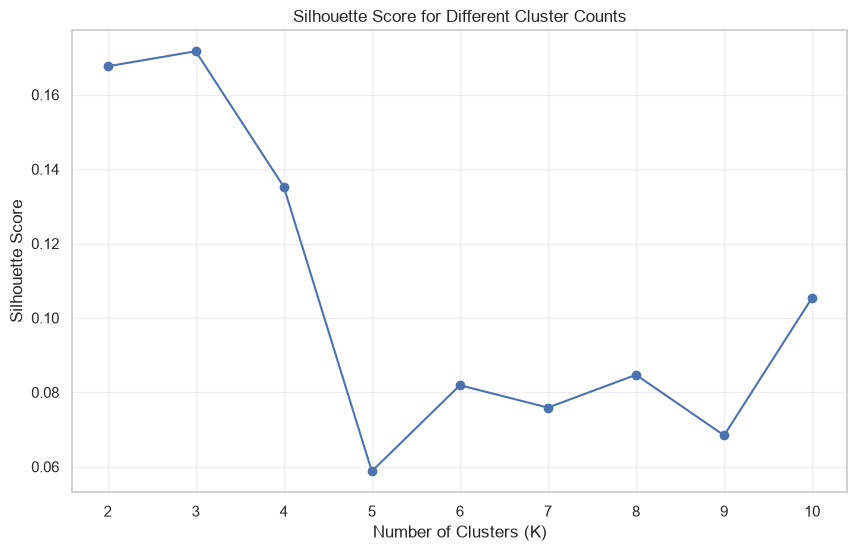

In [39]:

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different Cluster Counts")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

plt.show()



### 12.6 Final Selection of the Number of Clusters

The final number of clusters is selected by considering both the Elbow Curve and the Silhouette Score.

The Elbow Method helps identify where improvements in cluster compactness begin to diminish, while the Silhouette Score provides information about cluster separation.

Both results should be considered together before selecting the final value of K. The chosen value will be used to train the final K-Means model in the next section.


In [40]:

# Display candidate K values and their Silhouette Scores
silhouette_results = pd.DataFrame({
    "Number_of_Clusters": list(k_values),
    "Silhouette_Score": silhouette_values,
    "Inertia": inertia_values
})

silhouette_results = silhouette_results.sort_values(
    by="Silhouette_Score",
    ascending=False
).reset_index(drop=True)

display(silhouette_results)


,Number_of_Clusters,Silhouette_Score,Inertia
0,3,0.171678,420512.069718
1,2,0.167630,430759.812707
2,4,0.135256,408783.600952
3,10,0.105453,354199.238324
4,8,0.084701,366575.740239
5,6,0.081899,389377.441755
6,7,0.075891,380257.517445
7,9,0.068415,363740.390852
8,5,0.058770,399235.023321



## 13. Final K-Means Clustering Model

### 13.1 Introduction

K-Means is an unsupervised machine learning algorithm that groups data points into clusters based on feature similarity.

After preprocessing the Netflix dataset and evaluating candidate cluster counts, we use K-Means to assign each title to a cluster.

The model will use the scaled feature matrix prepared in Section 11. The resulting cluster labels will be added to a separate copy of the Netflix dataset for further analysis and interpretation.



### 13.2 Model Training

In this step, we initialize and train the K-Means model using the selected number of clusters.

The `n_init` parameter runs the algorithm with multiple initial centroid configurations and keeps the best solution according to inertia. The fixed `random_state` helps make the results reproducible.


In [41]:

# Set this value only after reviewing Sections 12.3 and 12.5
optimal_k = 3

if optimal_k is None:
    print("Review the Elbow Curve and Silhouette Scores, then set optimal_k.")
else:
    final_kmeans = KMeans(
        n_clusters=optimal_k,
        random_state=42,
        n_init=10
    )

    final_labels = final_kmeans.fit_predict(scaled_feature_df)

    print("K-Means model trained successfully.")
    print("Number of Clusters:", optimal_k)
    print("Inertia:", final_kmeans.inertia_)


K-Means model trained successfully.
Number of Clusters: 3
Inertia: 420512.06971832016



### 13.3 Assigning Cluster Labels

After training the K-Means model, each Netflix title receives a cluster label based on its processed features.

The cluster labels range from 0 to 2 because the model was trained with three clusters. These labels allow us to group titles for further analysis and interpretation.

We add the labels to a copy of the original dataset so that the original data remains unchanged.


In [42]:

# Create a copy of the original Netflix dataset
clustered_df = df.copy()

# Assign the predicted cluster labels
clustered_df["Cluster"] = final_labels

# Display the first five records
display(clustered_df[["title", "type", "release_year", "listed_in", "Cluster"]].head())

# Display the number of titles in each cluster
print("\nNumber of Titles per Cluster:")
display(clustered_df["Cluster"].value_counts().sort_index().to_frame("Title_Count"))


,title,type,release_year,listed_in,Cluster
0,3%,TV Show,2020,"International TV Shows, TV Dramas, TV Sci-Fi &...",2
1,07:19,Movie,2016,"Dramas, International Movies",0
2,23:59,Movie,2011,"Horror Movies, International Movies",0
3,9,Movie,2009,"Action & Adventure, Independent Movies, Sci-Fi...",0
4,21,Movie,2008,Dramas,0



Number of Titles per Cluster:


,Title_Count
Cluster,
0,5377
1,1573
2,837



### 13.4 Cluster Characteristics Analysis

Cluster analysis helps us understand how Netflix titles are distributed across the clusters produced by K-Means.

We examine the number of titles, the distribution of Movies and TV Shows, and the average release year for each cluster. These summaries help identify differences between clusters before assigning meaningful interpretations.

Cluster labels are algorithm-generated identifiers and do not imply any ranking or quality.


In [43]:

# Summarize the number of titles and average release year per cluster
cluster_summary = clustered_df.groupby("Cluster").agg(
    Total_Titles=("title", "count"),
    Average_Release_Year=("release_year", "mean")
).round(2)

print("Cluster Summary:")
display(cluster_summary)

# Compare Movies and TV Shows across clusters
type_distribution = pd.crosstab(
    clustered_df["Cluster"],
    clustered_df["type"]
)

print("Content Type Distribution by Cluster:")
display(type_distribution)


Cluster Summary:


,Total_Titles,Average_Release_Year
Cluster,,
0,5377,2012.92
1,1573,2015.94
2,837,2016.66


Content Type Distribution by Cluster:


type,Movie,TV Show
Cluster,,
0,5377,0
1,0,1573
2,0,837



### 13.5 Genre Distribution by Cluster

In this section, we examine the most common genres in each cluster.

Genre analysis helps us understand whether the clusters differ only by content type and release year or also show differences in genre composition.

We compare genre frequencies across clusters to support a more meaningful interpretation of the clustering results.


In [44]:

# Analyze the most frequent genres in each cluster
for cluster_id in sorted(clustered_df["Cluster"].unique()):
    print(f"\nCluster {cluster_id} — Top 10 Genres")

    cluster_genres = (
        clustered_df.loc[
            clustered_df["Cluster"] == cluster_id,
            "listed_in"
        ]
        .dropna()
        .str.split(", ")
        .explode()
    )

    display(
        cluster_genres.value_counts()
        .head(10)
        .to_frame("Title_Count")
    )



Cluster 0 — Top 10 Genres


,Title_Count
listed_in,
International Movies,2437
Dramas,2106
Comedies,1471
Documentaries,786
Action & Adventure,721
Independent Movies,673
Children & Family Movies,532
Romantic Movies,531
Thrillers,491



Cluster 1 — Top 10 Genres


,Title_Count
listed_in,
International TV Shows,654
TV Comedies,413
Kids' TV,402
Docuseries,348
Reality TV,221
Crime TV Shows,213
British TV Shows,213
Romantic TV Shows,208
Anime Series,140



Cluster 2 — Top 10 Genres


,Title_Count
listed_in,
TV Dramas,693
International TV Shows,545
Crime TV Shows,214
TV Action & Adventure,132
Romantic TV Shows,125
TV Comedies,112
TV Mysteries,90
TV Sci-Fi & Fantasy,74
TV Horror,67



### 13.6 Cluster Distribution Visualization

A bar chart provides a visual comparison of the number of Netflix titles assigned to each cluster.

This visualization helps identify the largest and smallest clusters and shows how evenly the dataset is distributed across the selected groups.


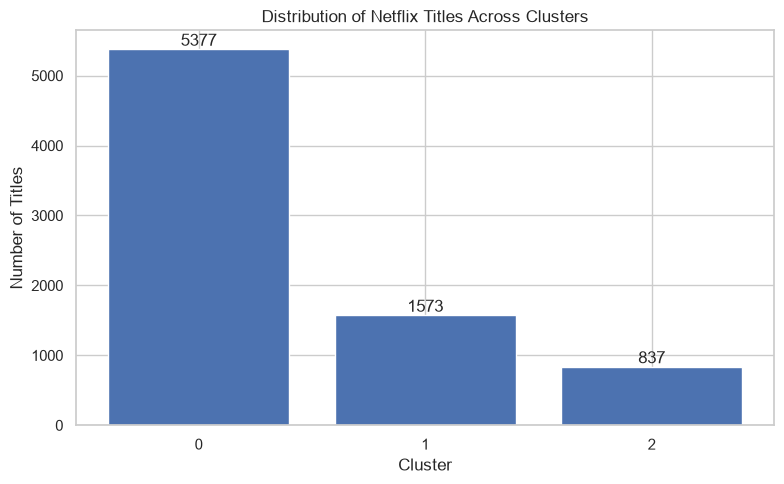

In [45]:

# Count titles in each cluster
cluster_counts = clustered_df["Cluster"].value_counts().sort_index()

# Plot the cluster distribution
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.title("Distribution of Netflix Titles Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Titles")

for position, count in enumerate(cluster_counts.values):
    plt.text(position, count, str(count), ha="center", va="bottom")

plt.tight_layout()
plt.show()



### 13.7 Content Type Distribution by Cluster

This visualization compares the number of Movies and TV Shows assigned to each cluster.

A grouped bar chart helps identify whether the clusters contain different types of Netflix content. This is useful for interpreting the clustering results alongside the genre analysis.


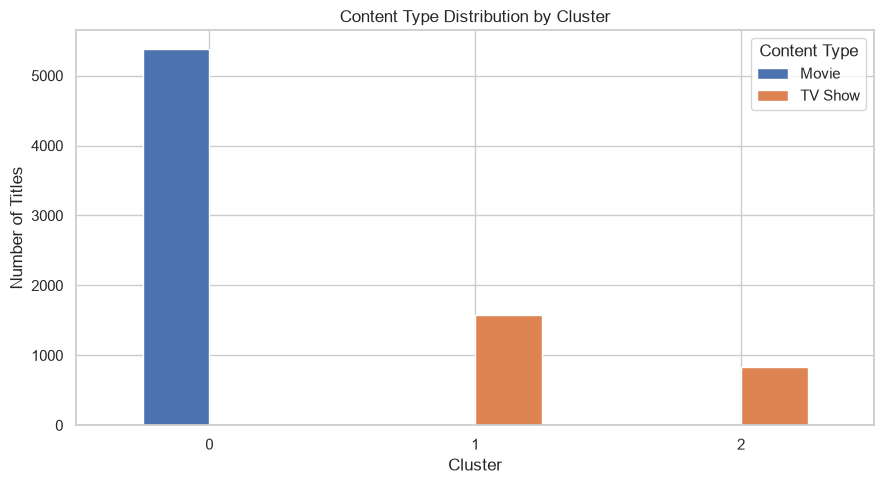

In [46]:

# Create a cross-tabulation of content types by cluster
type_distribution = pd.crosstab(
    clustered_df["Cluster"],
    clustered_df["type"]
)

# Plot the content type distribution
type_distribution.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Content Type Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()



### 13.8 Average Release Year by Cluster

This analysis compares the average release year of Netflix titles across the three clusters.

The comparison helps identify differences in the release-year distribution between the Movie cluster and the two TV Show clusters. The average release year is used as a descriptive statistic and does not, by itself, explain why the clusters formed.


Average Release Year by Cluster:


,Average_Release_Year
Cluster,
0,2012.92
1,2015.94
2,2016.66


<Figure size 800x500 with 0 Axes>

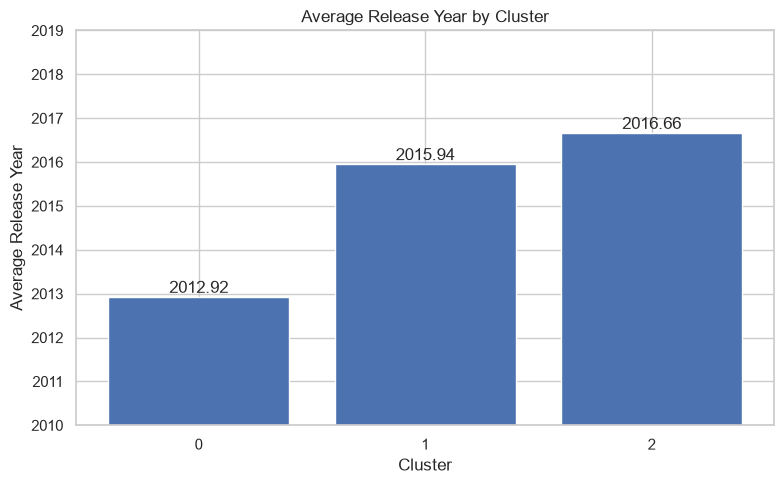

In [47]:

# Calculate the average release year for each cluster
average_release_year = clustered_df.groupby(
    "Cluster"
)["release_year"].mean()

print("Average Release Year by Cluster:")
display(average_release_year.round(2).to_frame("Average_Release_Year"))

# Visualize the average release year
plt.figure(figsize=(8, 5))


plt.figure(figsize=(8, 5))

plt.bar(
    average_release_year.index.astype(str),
    average_release_year.values
)

plt.title("Average Release Year by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Release Year")
plt.ylim(2010, 2019)

for position, year in enumerate(average_release_year.values):
    plt.text(
        position,
        year + 0.1,
        f"{year:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()



### 13.9 Final Clustering Model Evaluation

The Silhouette Score is used to evaluate how well the data points fit within their assigned clusters compared with other clusters.

We calculate the score for the final K-Means model using the same reproducible sample approach used during model selection. This helps assess the separation of the three clusters.

The score should be interpreted alongside the cluster distribution and genre analysis because a single metric does not fully describe clustering quality.


In [48]:

from sklearn.metrics import silhouette_score

# Use a reproducible sample to evaluate the final clustering
evaluation_sample = scaled_feature_df.sample(
    n=min(2000, len(scaled_feature_df)),
    random_state=42
)

# Get the final model's labels for the sampled records
evaluation_labels = final_kmeans.predict(evaluation_sample)

# Calculate the Silhouette Score
final_silhouette = silhouette_score(
    evaluation_sample,
    evaluation_labels
)

print("Selected Number of Clusters:", optimal_k)
print("Final Model Inertia:", round(final_kmeans.inertia_, 2))
print("Final Silhouette Score:", round(final_silhouette, 4))


Selected Number of Clusters: 3
Final Model Inertia: 420512.07
Final Silhouette Score: 0.1717



### 13.10 Final Cluster Summary and Interpretation

The final K-Means model groups Netflix titles into three clusters using encoded content types, ratings, genres, and standardized release years.

The cluster analysis shows that Cluster 0 contains Movies, while Clusters 1 and 2 contain TV Shows. The genre distributions indicate differences in the types of content represented in these groups.

The Silhouette Score of 0.1717 indicates limited separation overall. Therefore, the clustering results should be interpreted as exploratory groupings rather than definitive categories of Netflix content.


In [49]:

# Build a final summary of the three clusters
final_cluster_summary = clustered_df.groupby("Cluster").agg(
    Total_Titles=("title", "count"),
    Average_Release_Year=("release_year", "mean")
).round(2)

# Add the dominant content type for each cluster
dominant_type = (
    clustered_df.groupby("Cluster")["type"]
    .agg(lambda values: values.mode().iloc[0])
)

final_cluster_summary["Dominant_Content_Type"] = dominant_type

# Display the final summary
display(final_cluster_summary)

print("Selected K:", optimal_k)
print("Final Silhouette Score:", round(final_silhouette, 4))


,Total_Titles,Average_Release_Year,Dominant_Content_Type
Cluster,,,
0,5377,2012.92,Movie
1,1573,2015.94,TV Show
2,837,2016.66,TV Show


Selected K: 3
Final Silhouette Score: 0.1717



## 14. Director and Rating Analysis

### 14.1 Introduction

This analysis examines the distribution of Netflix content ratings across directors.

By comparing directors with their content ratings, we can identify patterns in the types of content associated with different directors. This analysis provides additional insight into the Netflix dataset beyond the clustering results.


In [50]:

# Select records with known director and rating values
director_rating_df = df.dropna(
    subset=["director", "rating"]
).copy()

# Count titles for each director and rating combination
director_rating_counts = (
    director_rating_df
    .groupby(["director", "rating"])
    .size()
    .reset_index(name="Title_Count")
    .sort_values("Title_Count", ascending=False)
)

# Display the 15 most frequent combinations
display(director_rating_counts.head(15))


,director,rating,Title_Count
4347,Unknown,TV-MA,985
4345,Unknown,TV-14,636
4348,Unknown,TV-PG,301
4350,Unknown,TV-Y7,182
4349,Unknown,TV-Y,181
4346,Unknown,TV-G,88
3472,"Raúl Campos, Jan Suter",TV-MA,17
2607,Marcus Raboy,TV-MA,13
1806,Jay Chapman,TV-MA,10
1811,Jay Karas,TV-MA,10



### 14.2 Director-Rating Frequency Analysis

This analysis counts Netflix titles for each director and content-rating combination. The initial results include the placeholder value "Unknown" where missing director information was previously filled.

A separate analysis excludes unknown director values to provide a more meaningful comparison among identifiable directors.



### 14.3 Visualization of Director and Rating Combinations

A bar chart displays the most frequent director-rating combinations. This makes it easier to compare the counts and identify which combinations occur most often in the dataset.


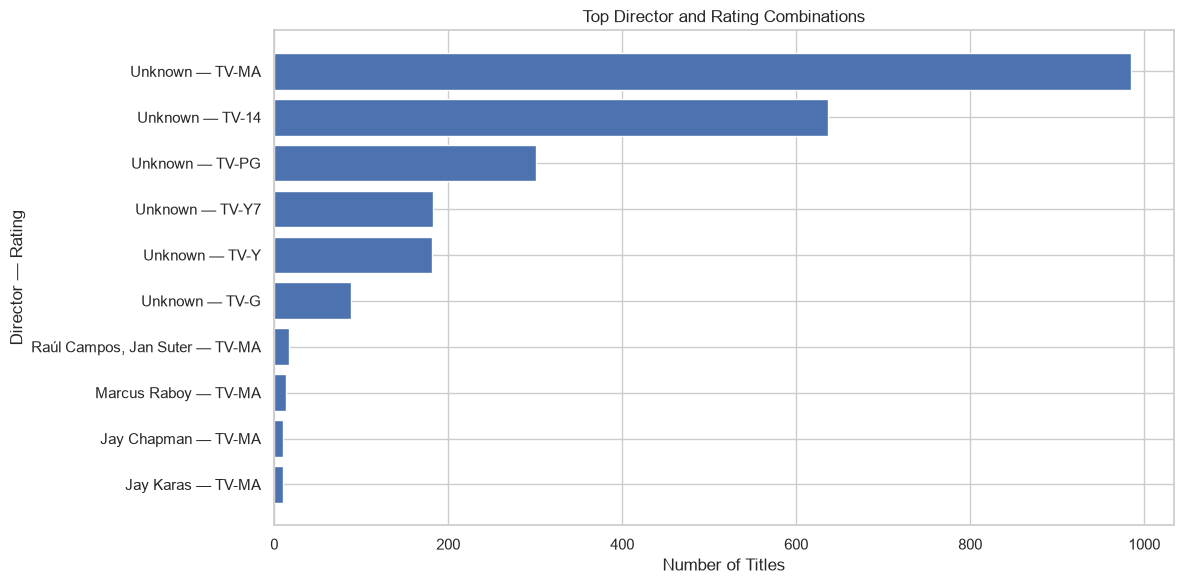

In [51]:

# Select the top 10 director-rating combinations
top_director_ratings = director_rating_counts.head(10).copy()

# Create readable labels for the chart
top_director_ratings["Director_Rating"] = (
    top_director_ratings["director"]
    + " — "
    + top_director_ratings["rating"]
)

# Plot the results
plt.figure(figsize=(12, 6))

plt.barh(
    top_director_ratings["Director_Rating"],
    top_director_ratings["Title_Count"]
)

plt.title("Top Director and Rating Combinations")
plt.xlabel("Number of Titles")
plt.ylabel("Director — Rating")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



### 14.4 Rating Analysis for Known Directors

Missing director values may have been replaced with the text "Unknown" during data cleaning. To focus on identifiable directors, we exclude both missing values and the literal "Unknown" label.

We then count titles by director and content rating to examine the most frequent combinations among known directors.


In [52]:

# Exclude missing and placeholder director values
known_directors_df = df[
    df["director"].notna()
    & df["director"].str.strip().ne("")
    & df["director"].str.strip().str.casefold().ne("unknown")
].copy()

# Exclude missing ratings
known_directors_df = known_directors_df.dropna(subset=["rating"])

# Count director-rating combinations
known_director_rating_counts = (
    known_directors_df
    .groupby(["director", "rating"])
    .size()
    .reset_index(name="Title_Count")
    .sort_values("Title_Count", ascending=False)
)

display(known_director_rating_counts.head(15))


,director,rating,Title_Count
3472,"Raúl Campos, Jan Suter",TV-MA,17
2607,Marcus Raboy,TV-MA,13
1806,Jay Chapman,TV-MA,10
1811,Jay Karas,TV-MA,10
3370,Quentin Tarantino,R,8
2682,Martin Scorsese,R,8
2335,Kunle Afolayan,TV-14,7
2358,Lance Bangs,TV-MA,7
4523,Youssef Chahine,TV-MA,7
3585,Robert Rodriguez,PG,7


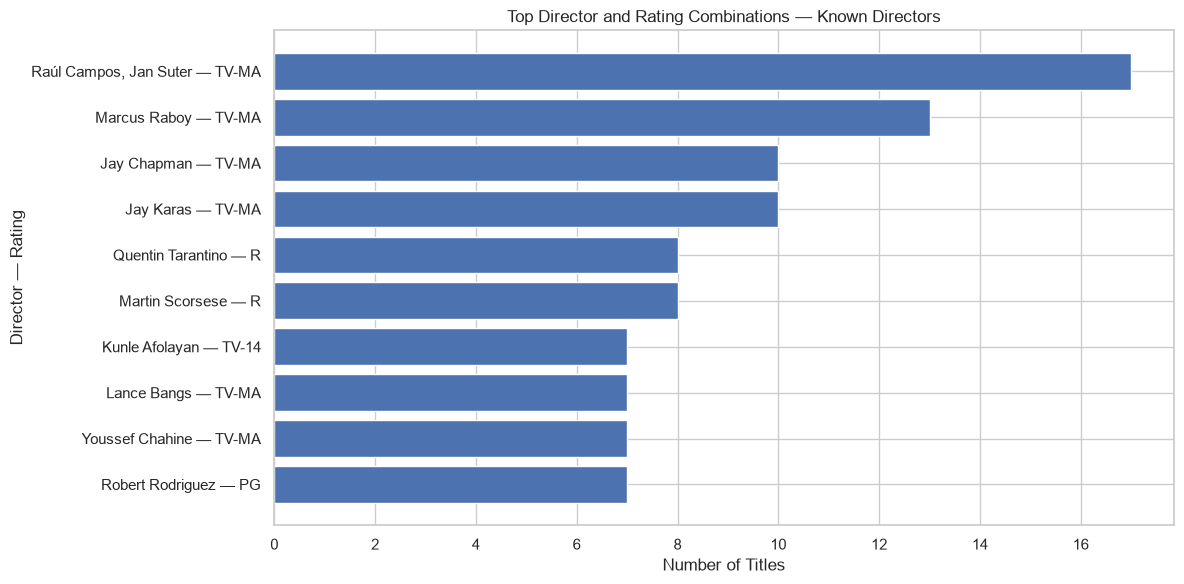

In [53]:

# Select the top 10 known director-rating combinations
top_known_director_ratings = known_director_rating_counts.head(10).copy()

# Create labels for the chart
top_known_director_ratings["Director_Rating"] = (
    top_known_director_ratings["director"]
    + " — "
    + top_known_director_ratings["rating"]
)

# Plot the results
plt.figure(figsize=(12, 6))

plt.barh(
    top_known_director_ratings["Director_Rating"],
    top_known_director_ratings["Title_Count"]
)

plt.title("Top Director and Rating Combinations — Known Directors")
plt.xlabel("Number of Titles")
plt.ylabel("Director — Rating")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



## 15. Country and Rating Analysis

### 15.1 Introduction

This section examines the distribution of Netflix content ratings across countries.

Some Netflix titles are associated with multiple countries and content ratings. By analyzing these variables, we can identify frequently occurring country-rating combinations and understand how ratings are represented across the Netflix catalog.

This analysis provides additional descriptive insights into the dataset.



### 15.2 Data Preparation

Some Netflix titles are associated with multiple countries. To analyze country-level rating distributions, we separate the country names so that each listed country can be analyzed individually.

Records with missing country or rating information are excluded from this analysis. The original dataset remains unchanged because the analysis is performed on a separate copy.


In [54]:

# Select records with known country and rating information
country_rating_df = df[
    df["country"].notna()
    & df["rating"].notna()
    & df["country"].str.strip().ne("")
    & df["country"].str.strip().str.casefold().ne("unknown")
].copy()

# Split multiple country names into separate rows
country_rating_df["country"] = (
    country_rating_df["country"].str.split(", ")
)

country_rating_df = country_rating_df.explode("country")

# Remove empty country names
country_rating_df["country"] = country_rating_df["country"].str.strip()

country_rating_df = country_rating_df[
    country_rating_df["country"].ne("")
]

print("Country-Rating Dataset Shape:", country_rating_df.shape)
display(country_rating_df.head())


Country-Rating Dataset Shape: (9063, 14)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_value,duration_unit
0,s1,TV Show,3%,Unknown,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,2020-08-14,2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...,4,Seasons
1,s2,Movie,07:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,2016-12-23,2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...,93,Minutes
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,2018-12-20,2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow...",78,Minutes
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,2017-11-16,2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi...",80,Minutes
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,2020-01-01,2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...,123,Minutes



### 15.3 Country and Rating Frequency Analysis

In this step, we count the number of titles associated with each country and content rating combination.

The resulting frequency table helps identify the combinations that occur most frequently in the dataset. These counts describe the available Netflix titles and do not establish a causal relationship between countries and content ratings.


In [55]:

# Count titles for each country and rating combination
country_rating_counts = (
    country_rating_df
    .groupby(["country", "rating"])
    .size()
    .reset_index(name="Title_Count")
    .sort_values("Title_Count", ascending=False)
)

# Display the 15 most frequent combinations
display(country_rating_counts.head(15))


,country,rating,Title_Count
480,United States,TV-MA,1033
190,India,TV-14,542
477,United States,R,539
478,United States,TV-14,464
476,United States,PG-13,340
481,United States,TV-PG,289
192,India,TV-MA,246
466,United Kingdom,TV-MA,236
475,United States,PG,207
413,Spain,TV-MA,156



### 15.4 Visualization of Country and Rating Combinations

A horizontal bar chart displays the most frequent country-rating combinations.

This visualization helps compare the number of titles across the selected combinations and identify the most frequently represented groups in the Netflix dataset.


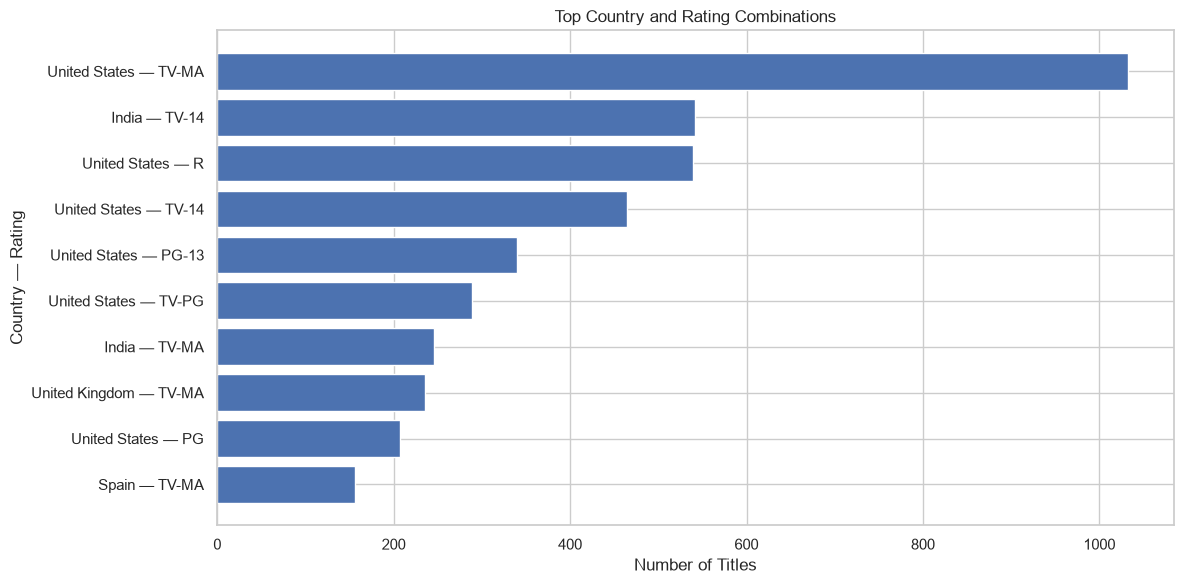

In [56]:

# Select the top 10 country-rating combinations
top_country_ratings = country_rating_counts.head(10).copy()

# Create labels for the visualization
top_country_ratings["Country_Rating"] = (
    top_country_ratings["country"]
    + " — "
    + top_country_ratings["rating"]
)

# Plot the results
plt.figure(figsize=(12, 6))

plt.barh(
    top_country_ratings["Country_Rating"],
    top_country_ratings["Title_Count"]
)

plt.title("Top Country and Rating Combinations")
plt.xlabel("Number of Titles")
plt.ylabel("Country — Rating")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



### 15.5 Summary

The country and rating analysis provides a descriptive overview of content ratings across the countries represented in the Netflix dataset.

The frequency table and visualization highlight the most common country-rating combinations. These results describe the observed dataset and should not be interpreted as evidence that a country determines a title's content rating.



## 16. Conclusion and Future Improvements

### 16.1 Project Conclusion

This project explored the Netflix Movies and TV Shows dataset using data analysis and unsupervised machine learning techniques. The workflow included data inspection, missing-value handling, data cleaning, exploratory data analysis, feature encoding, feature scaling, and K-Means clustering.

The Elbow Method and Silhouette Score were used to compare candidate cluster counts. Based on the evaluated results, a K-Means model with three clusters was selected for further analysis.

The final model assigned 7,787 Netflix titles to three clusters:
- Cluster 0 contained 5,377 Movies.
- Cluster 1 contained 1,573 TV Shows.
- Cluster 2 contained 837 TV Shows.

Genre analysis showed differences between the clusters. Cluster 0 included a broad range of movie genres, while Clusters 1 and 2 contained TV Shows with different genre distributions.

The final Silhouette Score was 0.1717, indicating limited separation between clusters. Therefore, the results should be interpreted as exploratory groupings rather than strongly separated categories.

Overall, the project demonstrates how data preprocessing, exploratory analysis, and clustering can be applied to investigate patterns in a streaming-content dataset.



### 16.2 Project Limitations

The project has several limitations:

- The Silhouette Score of 0.1717 indicates relatively weak cluster separation.
- The selected features caused the model to separate Movies from TV Shows, so the clusters may reflect content type more strongly than deeper content similarities.
- The dataset contains missing values in some original columns, which may affect analyses involving those fields.
- The current model does not use the description text as a numerical feature, even though descriptions may contain useful information about content similarity.
- The results depend on the selected features, preprocessing decisions, scaling method, and number of clusters.

These limitations should be considered when interpreting the clustering results.



### 16.3 Future Improvements

Future work could improve the project in the following ways:

- Use TF-IDF to represent the textual descriptions of Netflix titles.
- Compare alternative feature-selection and feature-weighting strategies.
- Evaluate K-Means against hierarchical clustering when appropriate.
- Compare clustering quality using Silhouette Scores and cluster-size distributions.
- Investigate whether the resulting clusters represent meaningful content similarities beyond the Movie and TV Show distinction.

These improvements may help produce more informative and interpretable clusters.



## 17. Model Explainability and Cluster Profiles

### 17.1 Introduction

Model explainability helps us understand why data points are grouped into particular clusters.

K-Means is an unsupervised learning algorithm, so it does not provide feature-importance scores in the same way as many supervised models. In this project, cluster profiles are used to interpret the resulting groups through their content types, release years, and genre distributions.

These profiles help describe the characteristics of each cluster and assess whether the groupings are useful for understanding the Netflix catalog.



### 17.2 Cluster Profile Analysis

In this step, we summarize each cluster using the number of titles, average release year, and most common content type.

The resulting table provides a compact overview of the differences between the clusters. These descriptive characteristics support interpretation but do not prove that the clusters are strongly separated.


In [57]:

# Summarize the characteristics of each cluster
cluster_profiles = clustered_df.groupby("Cluster").agg(
    Total_Titles=("title", "count"),
    Average_Release_Year=("release_year", "mean"),
    Most_Common_Content_Type=(
        "type",
        lambda values: values.mode().iloc[0]
    )
).round(2)

# Display the cluster profiles
display(cluster_profiles)


,Total_Titles,Average_Release_Year,Most_Common_Content_Type
Cluster,,,
0,5377,2012.92,Movie
1,1573,2015.94,TV Show
2,837,2016.66,TV Show



### 17.3 Interpretation of Cluster Profiles

The cluster profiles reveal the following characteristics:

- **Cluster 0:** Contains 5,377 titles, with an average release year of 2012.92. Movies are the dominant content type.
- **Cluster 1:** Contains 1,573 titles, with an average release year of 2015.94. TV Shows are the dominant content type.
- **Cluster 2:** Contains 837 titles, with an average release year of 2016.66. TV Shows are the dominant content type.

The profiles show that the current model separates Movies from TV Shows and divides TV Shows into two additional groups. The earlier genre analysis provides more detail about the content represented in these groups.

The Silhouette Score of 0.1717 indicates limited separation overall. Therefore, the clusters should be treated as exploratory groups rather than strongly distinct categories.



### 17.4 Explainability Limitation

K-Means assigns titles to clusters based on distances in the prepared feature space. The cluster profiles summarize observable differences between the groups, but they do not establish that any single feature caused a title to be assigned to a particular cluster.

This project uses descriptive cluster profiling rather than SHAP or LIME, which are more commonly applied to explaining individual predictions from supervised machine-learning models.

Further work could examine cluster centroids and compare feature distributions across clusters to understand their differences in greater detail.



## 18. Stakeholder Strategies and Recommendations

### 18.1 Introduction

Cluster analysis can help stakeholders understand the composition of a content catalog and identify opportunities for content organization and analysis.

In this project, the three clusters are examined to suggest possible strategies for content categorization, catalog planning, and further analysis. These recommendations are based on the observed cluster sizes, content types, and genre distributions.

The recommendations are exploratory because the clustering model has a Silhouette Score of 0.1717, indicating limited separation between clusters.



### 18.2 Cluster-Based Strategies

**Cluster 0 — Movie Collection**

This cluster contains 5,377 titles and consists of Movies. Its genre distribution includes International Movies, Dramas, Comedies, and Documentaries.

**Possible strategies:**
- Organize movie titles into useful genre-based catalog categories.
- Examine the balance between popular genres and less represented genres.
- Use genre and release-year information to support catalog reporting.

**Cluster 1 — TV Show Collection**

This cluster contains 1,573 titles and consists of TV Shows. Its leading genres include International TV Shows, TV Comedies, Kids' TV, and Docuseries.

**Possible strategies:**
- Organize TV Shows by genre and audience category.
- Examine the representation of comedy, children's programming, and documentary series.
- Compare this cluster with other TV Show groups to identify differences in genre composition.

**Cluster 2 — TV Drama-Oriented Collection**

This cluster contains 837 titles and consists of TV Shows. Its leading genres include TV Dramas, International TV Shows, Crime TV Shows, and TV Action & Adventure.

**Possible strategies:**
- Create catalog groupings around drama, crime, and action-oriented TV content.
- Examine genre overlap with Cluster 1 to understand differences between the two TV Show groups.
- Investigate whether additional features could produce more meaningful TV Show segments.

These strategies are suggestions for catalog analysis, not proven business outcomes. The dataset does not contain viewing behavior, customer preferences, or revenue data to establish their commercial impact.



### 18.3 Summary

The cluster analysis provides three exploratory groups that can be described by their content type and genre distributions.

Cluster 0 represents the Movie collection, while Clusters 1 and 2 represent different groups of TV Shows. These groupings may support catalog organization and further content analysis.

However, the Silhouette Score of 0.1717 indicates limited cluster separation. The recommendations should therefore be treated as hypotheses for further investigation rather than definitive business conclusions.



### 18.4 Cluster Strategy Summary

The following table summarizes the number of titles, dominant content type, and possible catalog strategy for each cluster. The strategies are exploratory recommendations based on the observed cluster characteristics.


In [58]:

# Define stakeholder strategies based on the observed cluster profiles
cluster_strategies = {
    0: "Organize movie titles by genre and release year",
    1: "Explore comedy, children's content, and docuseries",
    2: "Explore drama, crime, and action-oriented TV shows"
}

# Create a summary table from the existing cluster results
strategy_summary = final_cluster_summary.copy()

strategy_summary["Suggested_Strategy"] = (
    strategy_summary.index.map(cluster_strategies)
)

# Display the stakeholder strategy summary
display(strategy_summary)


,Total_Titles,Average_Release_Year,Dominant_Content_Type,Suggested_Strategy
Cluster,,,,
0,5377,2012.92,Movie,Organize movie titles by genre and release year
1,1573,2015.94,TV Show,"Explore comedy, children's content, and docuse..."
2,837,2016.66,TV Show,"Explore drama, crime, and action-oriented TV s..."



## 19. Hierarchical Clustering and Dendrogram

### 19.1 Introduction

Hierarchical clustering is an unsupervised learning technique that groups observations into a hierarchy of clusters.

A dendrogram is a tree-shaped visualization that shows how observations or groups are merged at different distances. It can help explore the hierarchical structure of a dataset and compare it with the K-Means clustering results.

Because the Netflix dataset contains thousands of titles, a representative sample is used for dendrogram visualization to keep the computation manageable. The dendrogram is exploratory and does not replace the existing K-Means model.



### 19.2 Preparing Data for Hierarchical Clustering

A reproducible sample of the existing scaled feature matrix is selected for hierarchical clustering. Using the same prepared features helps maintain consistency with the current K-Means workflow.

The sample is used only to visualize the hierarchical structure; the original dataset and K-Means assignments remain unchanged.


In [59]:

# Select a reproducible sample for dendrogram analysis
hierarchical_sample_size = min(300, len(scaled_feature_df))

hierarchical_sample = scaled_feature_df.sample(
    n=hierarchical_sample_size,
    random_state=42
)

print("Hierarchical Clustering Sample Shape:", hierarchical_sample.shape)


Hierarchical Clustering Sample Shape: (300, 60)



### 19.3 Dendrogram Visualization

The dendrogram is generated using Ward's linkage method, which merges groups based on increases in within-cluster variance.

The vertical axis represents the linkage distance at which groups are merged. Large vertical gaps may suggest potential levels at which the hierarchy could be divided into smaller groups.


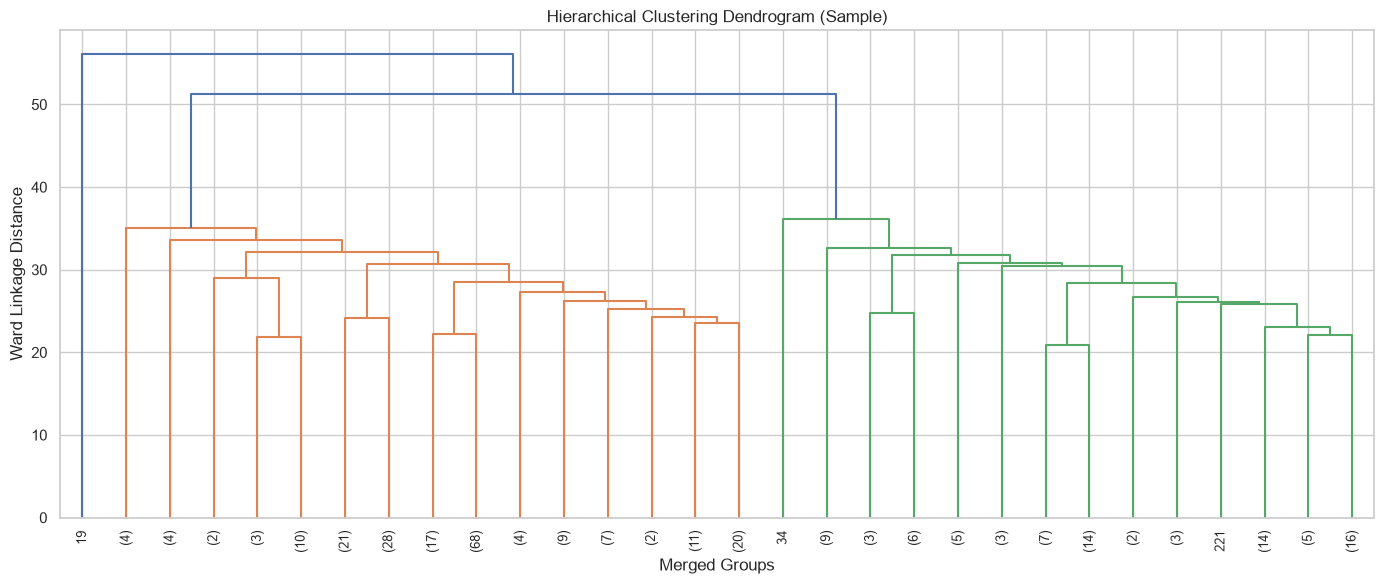

In [60]:

from scipy.cluster.hierarchy import linkage, dendrogram

# Calculate hierarchical linkage on the sampled feature matrix
hierarchical_linkage = linkage(
    hierarchical_sample.to_numpy(),
    method="ward"
)

# Plot the dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    hierarchical_linkage,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Hierarchical Clustering Dendrogram (Sample)")
plt.xlabel("Merged Groups")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()



### 19.4 Interpretation of the Dendrogram

The dendrogram was generated using Ward's linkage method on a reproducible sample of 300 Netflix titles represented by 60 scaled features.

The visualization shows that observations and smaller groups merge at different linkage distances. Some final merges occur at substantially larger distances, suggesting differences between the groups being combined.

The dendrogram provides an exploratory view of the hierarchical structure in the sample. It does not independently establish that three clusters are optimal, and its structure may differ when the full dataset is analyzed.

The existing K-Means model with three clusters is retained for the main project analysis. The dendrogram is used as a supplementary visualization rather than as a replacement for the K-Means results.
